# Fresh produce shortage early warning

## Problem

Fresh produce availability swings with the seasons, the weather, fuel costs and supply disruptions. Weather affects supply with a delay of a month or two, so it should give some advance notice of trouble. A store that knows a shortage is likely next month can reorder, switch suppliers or warn customers.

**Task.** At the end of month *t*, predict whether a given product at a given store will have a **shortage** (`availability_pct < 82`, flagged as `shortage_flag = 1`) in month *t+h*, for *h* = 1, 2 and 3 months. The main metric is **PR-AUC** (average precision, the area under the precision-recall curve), where a model with no skill scores about 0.08. Also report ROC-AUC and precision, recall and F1 at a chosen threshold.

**The data is simulated** (see `generate_produce_data.py`).

## Contents
1. Data source, preparation and cleaning
2. EDA (distributions, missing values, outliers, correlations)
3. Features, targets and the time-based split
4. Leakage checks
5. Feature importance
6. Model selection: baselines and four model families
7. Cross-validation and hyperparameter tuning
8. Threshold: precision, recall, F1
9. Final evaluation on the untouched test years

In [66]:
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import average_precision_score, mutual_info_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import ParameterSampler
from IPython.display import display

# Make sure the notebook runs from the project folder (where produce_features.py
# and data/ live), even if the kernel was started somewhere else.
import sys
from pathlib import Path

_starts = [Path.cwd()]
if "__vsc_ipynb_file__" in globals():          # VS Code tells the kernel where the notebook file is
    _starts.insert(0, Path(__vsc_ipynb_file__).resolve().parent)
_root = next((d for s in _starts for d in [s, *s.parents] if (d / "produce_features.py").exists()), None)
if _root is None:
    raise FileNotFoundError(
        f"produce_features.py not found from {[str(s) for s in _starts]}. "
        "Open the notebook from the project folder, or set _root to that folder by hand."
    )
os.chdir(_root)
sys.path.insert(0, str(_root))

import produce_features as pf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

DATA = "data/synthetic_produce_prices_1990_2025.csv"
HORIZONS = list(pf.HORIZONS)

## 1. Data source, preparation and cleaning

**Source and retrieval.** The CSV is committed at `data/synthetic_produce_prices_1990_2025.csv`. 

Data contains 12 products at 4 stores (one per US region) month by month from 1990 to 2025 using explicit rules for seasonality, regional weather, inflation, fuel cost, import disruptions, promotions and covid, then drops 3.5% of store-months at random to mimic missing reports. The first cell below checks that regenerating gives the same file.

One row is one product at one store in one month. Check types, missing values, duplicates, impossible values and internal consistency before using anything.

In [67]:
raw = pd.read_csv(DATA)
print(raw.shape)
display(raw.head(3))
display(raw.dtypes.to_frame("dtype").T)

(10000, 25)


,record_id,date,year,month,store_id,store_name,region,store_tier,product,unit,avg_temp_c,temp_anomaly_c,precip_mm,drought_index,frost_days,heatwave_days,enso_index,cpi_index,fuel_cost_index,import_disruption_index,promotion_flag,covid_period,price_usd_per_lb,availability_pct,shortage_flag
0,1,1990-01-01,1990,1,S01,FreshMart Northeast,Northeast,premium,apples,lb,-3.9,-1.9,87.6,0.0,7,0,-0.04,100.0,101.2,-0.69,1,0,0.72,95.0,0
1,2,1990-01-01,1990,1,S01,FreshMart Northeast,Northeast,premium,avocados,lb,-3.9,-1.9,87.6,0.0,7,0,-0.04,100.0,101.2,-0.69,0,0,1.77,82.9,0
2,3,1990-01-01,1990,1,S01,FreshMart Northeast,Northeast,premium,bananas,lb,-3.9,-1.9,87.6,0.0,7,0,-0.04,100.0,101.2,-0.69,0,0,0.43,94.4,0


,record_id,date,year,month,store_id,store_name,region,store_tier,product,unit,avg_temp_c,temp_anomaly_c,precip_mm,drought_index,frost_days,heatwave_days,enso_index,cpi_index,fuel_cost_index,import_disruption_index,promotion_flag,covid_period,price_usd_per_lb,availability_pct,shortage_flag
dtype,int64,str,int64,int64,str,str,str,str,str,str,float64,float64,float64,float64,int64,int64,float64,float64,float64,float64,int64,int64,float64,float64,int64


In [68]:
df = raw.copy()
df["date"] = pd.to_datetime(df["date"])

checks = pd.Series({
    "missing cells": int(df.isna().sum().sum()),
    "duplicate rows": int(df.duplicated().sum()),
    "duplicate (date, store, product)": int(df.duplicated(["date", "store_id", "product"]).sum()),
    "non-positive prices": int((df["price_usd_per_lb"] <= 0).sum()),
    "availability outside 0-100": int((~df["availability_pct"].between(0, 100)).sum()),
    "dates not on the 1st of a month": int((df["date"].dt.day != 1).sum()),
    "shortage_flag disagrees with availability < 82": int(((df["availability_pct"] < 82).astype(int) != df["shortage_flag"]).sum()),
    "frost/heat days outside 0-31": int((~df["frost_days"].between(0, 31) | ~df["heatwave_days"].between(0, 31)).sum()),
})
display(checks.to_frame("count"))
assert (checks == 0).all()

,count
missing cells,0
duplicate rows,0
"duplicate (date, store, product)",0
non-positive prices,0
availability outside 0-100,0
dates not on the 1st of a month,0
shortage_flag disagrees with availability < 82,0
frost/heat days outside 0-31,0


In [69]:
display(df.describe().T[["min", "25%", "50%", "75%", "max"]].round(2))
for c in ["store_id", "region", "store_tier", "product", "unit"]:
    print(c, "->", sorted(df[c].unique()))

,min,25%,50%,75%,max
record_id,1.0,2500.75,5000.5,7500.25,10000.0
date,1990-01-01 00:00:00,1999-01-01 00:00:00,2007-12-16 12:00:00,2017-01-01 00:00:00,2025-12-01 00:00:00
year,1990.0,1999.0,2007.5,2017.0,2025.0
month,1.0,3.0,6.0,9.0,12.0
avg_temp_c,-6.4,8.9,15.0,21.1,31.7
temp_anomaly_c,-4.41,-0.57,0.49,1.49,5.59
precip_mm,6.9,51.0,78.35,109.6,308.3
drought_index,-4.72,-1.64,-0.68,0.34,3.98
frost_days,0.0,0.0,0.0,2.0,19.0
heatwave_days,0.0,0.0,0.0,0.0,17.0


store_id -> ['S01', 'S02', 'S03', 'S04']
region -> ['Midwest', 'Northeast', 'South', 'West']
store_tier -> ['discount', 'mainstream', 'premium']
product -> ['apples', 'avocados', 'bananas', 'broccoli', 'carrots', 'grapes', 'lettuce', 'onions', 'oranges', 'potatoes', 'strawberries', 'tomatoes']
unit -> ['lb']


In [70]:
# Months with no price report: each store-product series should have one row per month.
months = pd.date_range(df["date"].min(), df["date"].max(), freq="MS")
per_series = df.groupby(["store_id", "product"]).size()
print(f"{len(months)} months, {len(per_series)} series; rows per series: min {per_series.min()}, max {per_series.max()}")
print(f"overall share of months with no report: {1 - len(df) / (len(months) * len(per_series)):.1%}")

# Longest run of consecutive missing months in any series
longest = 0
for _, g in df.groupby(["store_id", "product"]):
    idx = months.get_indexer(g["date"])
    gaps = np.diff(np.concatenate([[-1], idx, [len(months)]])) - 1
    longest = max(longest, gaps.max())
print("longest run of consecutive missing months in any series:", longest)

432 months, 24 series; rows per series: min 412, max 427
overall share of months with no report: 3.5%
longest run of consecutive missing months in any series: 3


## 2. EDA

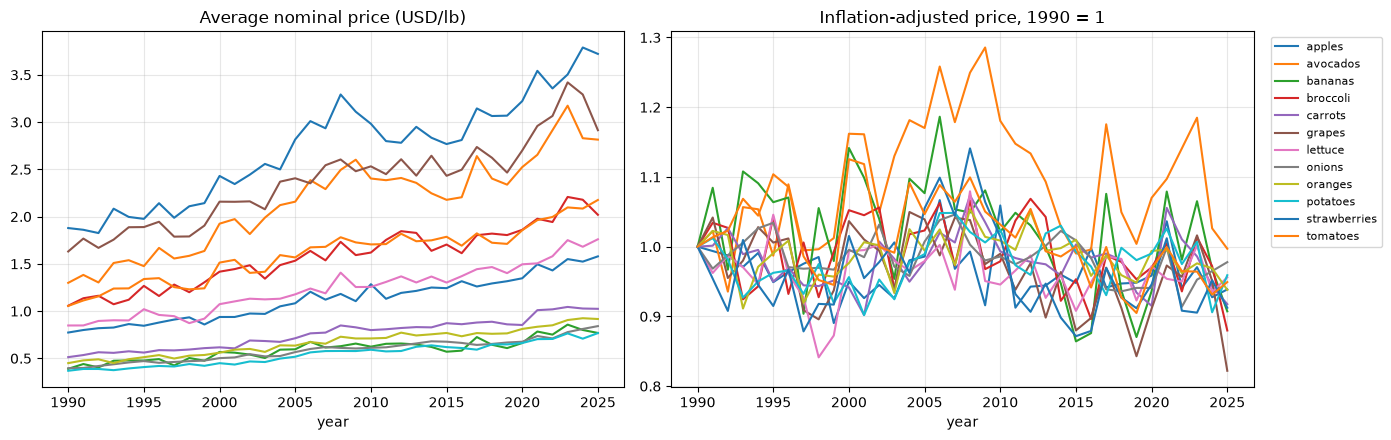

In [71]:
# Prices over time: nominal, and with inflation removed
df["real_price"] = np.exp(pf.real_log_price(df["price_usd_per_lb"], df["cpi_index"]))
nominal = df.groupby(["year", "product"])["price_usd_per_lb"].mean().unstack()
real = df.groupby(["year", "product"])["real_price"].mean().unstack()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
nominal.plot(ax=ax[0], legend=False)
ax[0].set_title("Average nominal price (USD/lb)")
(real / real.iloc[0]).plot(ax=ax[1])
ax[1].set_title("Inflation-adjusted price, 1990 = 1")
ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

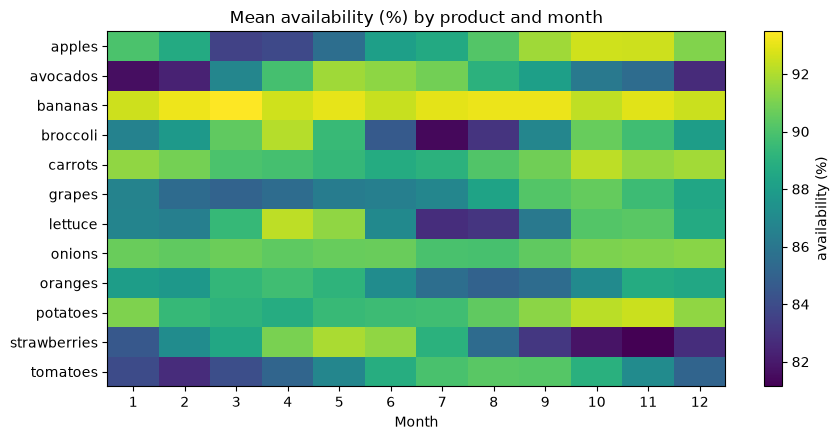

In [72]:
# Seasonality of availability by product
seasonal = df.groupby(["product", "month"])["availability_pct"].mean().unstack()
fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(seasonal.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(len(seasonal)))
ax.set_yticklabels(seasonal.index)
ax.set_xticks(range(12))
ax.set_xticklabels(range(1, 13))
ax.set_xlabel("Month")
ax.set_title("Mean availability (%) by product and month")
ax.grid(False)
plt.colorbar(im, label="availability (%)")
plt.tight_layout()
plt.show()

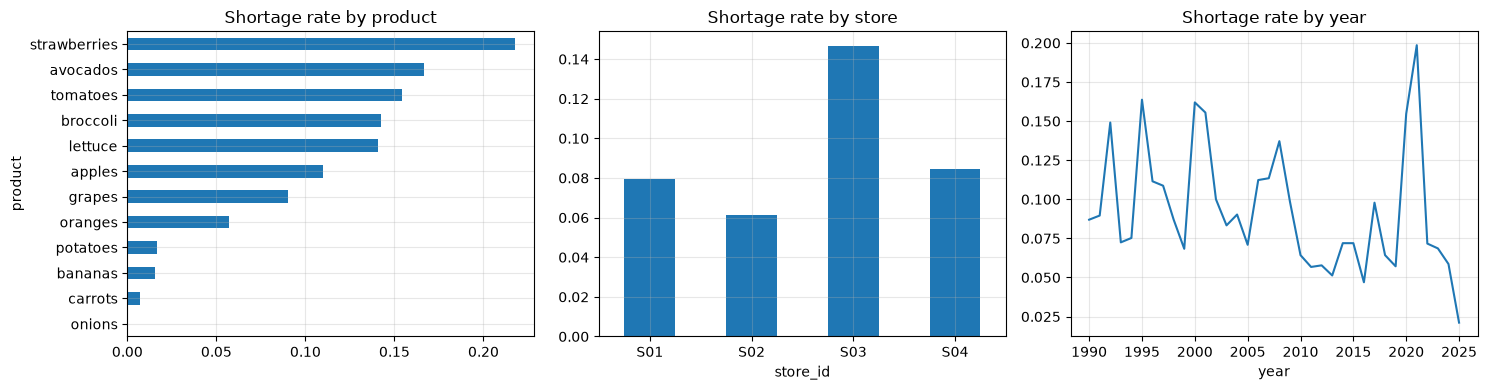

overall shortage rate: 9.3%


In [73]:
# Where do shortages happen?
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.groupby("product")["shortage_flag"].mean().sort_values().plot.barh(ax=ax[0], title="Shortage rate by product")
df.groupby("store_id")["shortage_flag"].mean().plot.bar(ax=ax[1], title="Shortage rate by store", rot=0)
df.groupby("year")["shortage_flag"].mean().plot(ax=ax[2], title="Shortage rate by year")
plt.tight_layout()
plt.show()
print(f"overall shortage rate: {df['shortage_flag'].mean():.1%}")

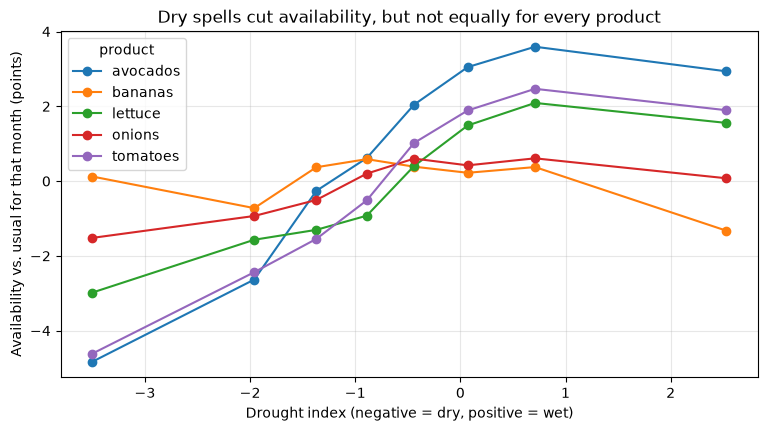

,drought_index,temp_anomaly_c,frost_days,heatwave_days,precip_mm
apples,0.35,-0.26,-0.01,-0.11,0.03
avocados,0.66,-0.23,-0.03,-0.13,0.11
bananas,-0.05,-0.02,-0.01,-0.01,-0.03
broccoli,0.34,-0.50,0.05,-0.21,0.05
carrots,0.42,-0.26,0.01,-0.11,0.04
grapes,0.30,-0.36,0.04,-0.14,0.03
lettuce,0.41,-0.54,-0.00,-0.18,0.07
onions,0.17,-0.13,-0.02,-0.06,-0.01
oranges,0.40,-0.19,-0.01,-0.08,0.06
potatoes,0.39,-0.18,0.00,-0.07,-0.02


In [74]:
# Weather effect on availability, after removing the usual seasonal pattern
d = df.copy()
d["avail_resid"] = d["availability_pct"] - d.groupby(["store_id", "product", "month"])["availability_pct"].transform("mean")

d["drought_bin"] = pd.qcut(d["drought_index"], 8)
sel = ["tomatoes", "avocados", "lettuce", "bananas", "onions"]
tab = d[d["product"].isin(sel)].groupby(["drought_bin", "product"], observed=True)["avail_resid"].mean().unstack()
tab.index = [round(iv.mid, 2) for iv in tab.index]
tab.plot(marker="o")
plt.xlabel("Drought index (negative = dry, positive = wet)")
plt.ylabel("Availability vs. usual for that month (points)")
plt.title("Dry spells cut availability, but not equally for every product")
plt.show()

wcols = ["drought_index", "temp_anomaly_c", "frost_days", "heatwave_days", "precip_mm"]
corr = pd.DataFrame({p: g[wcols].corrwith(g["avail_resid"]) for p, g in d.groupby("product")}).T
display(corr.round(2))

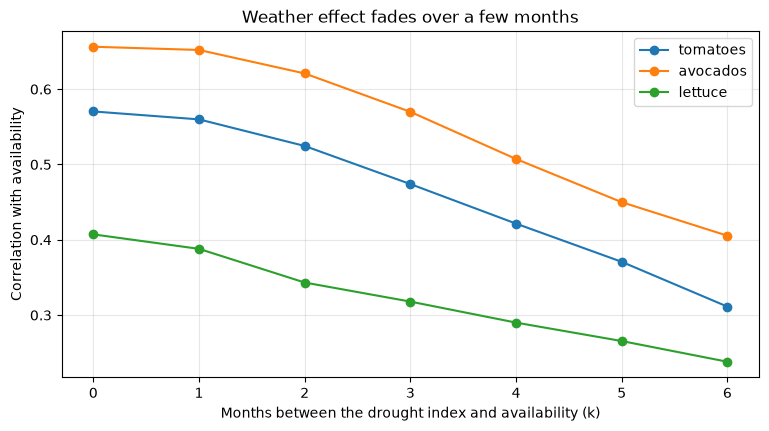

In [75]:
# How long does weather take to show up in availability?
# Correlate availability with the drought index k months EARLIER (matched by date).
res = {}
for prod in ["tomatoes", "avocados", "lettuce"]:
    dp = d[d["product"] == prod]
    vals = []
    for k in range(0, 7):
        lagged = dp[["store_id", "date", "drought_index"]].copy()
        lagged["date"] = lagged["date"] + pd.DateOffset(months=k)
        m = dp.merge(lagged, on=["store_id", "date"], suffixes=("", "_lag"))
        vals.append(m["avail_resid"].corr(m["drought_index_lag"]))
    res[prod] = vals
pd.DataFrame(res, index=range(0, 7)).plot(marker="o")
plt.xlabel("Months between the drought index and availability (k)")
plt.ylabel("Correlation with availability")
plt.title("Weather effect fades over a few months")
plt.show()

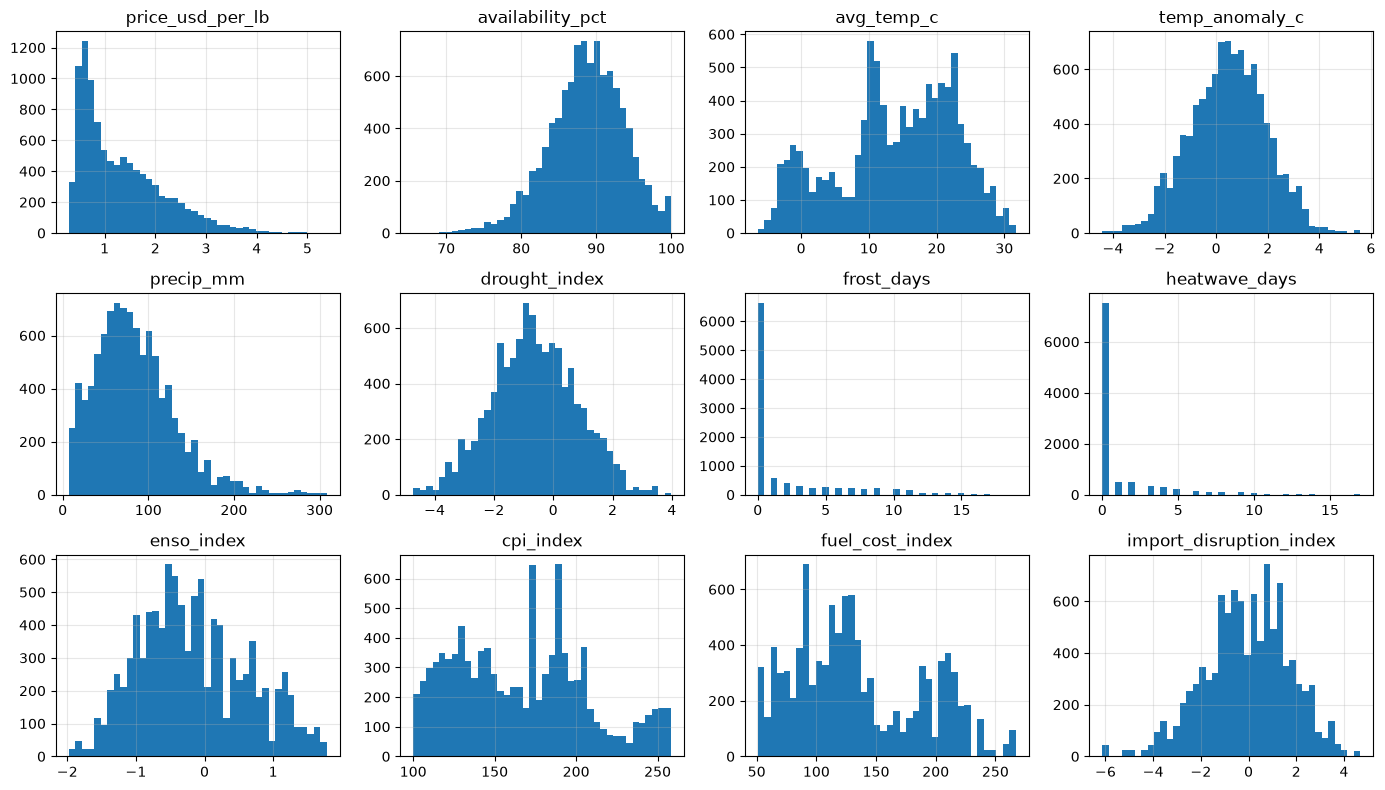

skewness:
price_usd_per_lb           1.15
availability_pct          -0.36
avg_temp_c                -0.36
temp_anomaly_c            -0.06
precip_mm                  1.00
drought_index              0.04
frost_days                 1.97
heatwave_days              2.94
enso_index                 0.31
cpi_index                  0.35
fuel_cost_index            0.47
import_disruption_index   -0.29


In [76]:
# Distributions of the numeric columns
num = ["price_usd_per_lb", "availability_pct", "avg_temp_c", "temp_anomaly_c", "precip_mm", "drought_index",
       "frost_days", "heatwave_days", "enso_index", "cpi_index", "fuel_cost_index", "import_disruption_index"]
df[num].hist(bins=40, figsize=(14, 8), layout=(3, 4))
plt.tight_layout()
plt.show()
print("skewness:"); print(df[num].skew().round(2).to_string())

In [77]:
# Outliers: values beyond 3 standard deviations, and the 1.5 x IQR rule
rows = []
for c in num:
    x = df[c]
    z = ((x - x.mean()).abs() > 3 * x.std()).sum()
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    iqr_out = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
    rows.append({"column": c, "beyond 3 sd": int(z), "beyond 1.5 IQR": int(iqr_out), "min": x.min(), "max": x.max()})
display(pd.DataFrame(rows).set_index("column").round(2))
print("share of rows with availability >= 99.5:", round((df["availability_pct"] >= 99.5).mean(), 3))

,beyond 3 sd,beyond 1.5 IQR,min,max
column,,,,
price_usd_per_lb,106,195,0.29,5.38
availability_pct,59,117,65.60,100.00
avg_temp_c,0,0,-6.40,31.70
temp_anomaly_c,30,48,-4.41,5.59
precip_mm,125,249,6.90,308.30
drought_index,5,62,-4.72,3.98
frost_days,211,1577,0.00,19.00
heatwave_days,344,2462,0.00,17.00
enso_index,0,0,-1.98,1.78


share of rows with availability >= 99.5: 0.012


**Correlations** Availability itself is the strongest correlate of the shortage flag (-0.62, partly by construction since the flag is a threshold on availability), then price (+0.27), heatwave days (+0.17), the drought index (-0.17, dry means shortage) and the temperature anomaly (+0.14). Same-month correlations are weak for the other columns because weather acts with a delay and differently for each product, which is why the models use lags and a per-product view.

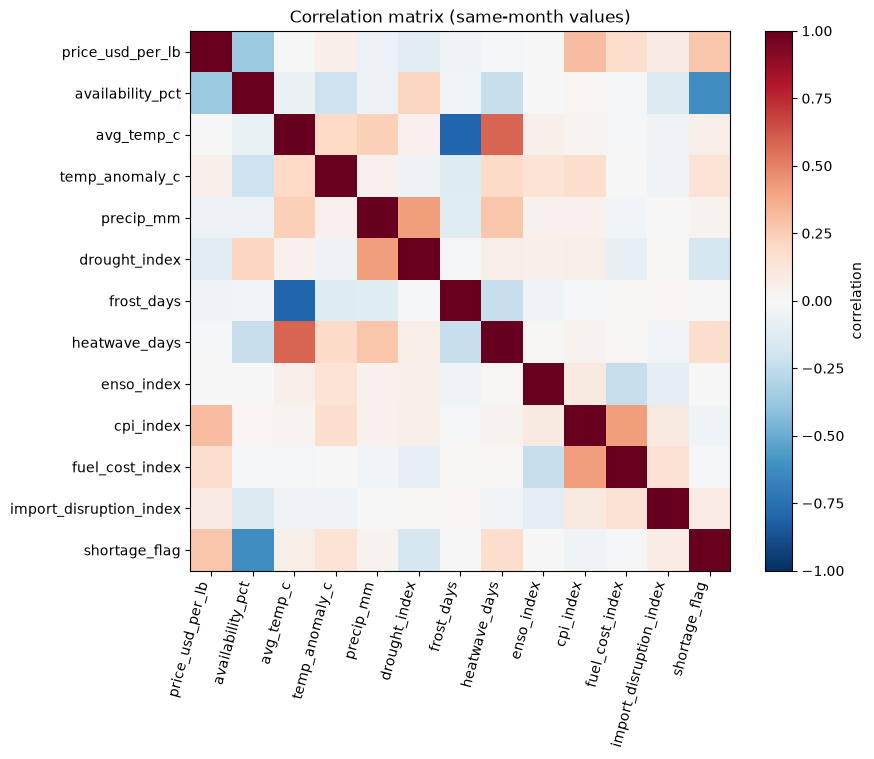

correlation with shortage_flag:
availability_pct          -0.62
drought_index             -0.17
cpi_index                 -0.04
fuel_cost_index           -0.01
frost_days                -0.00
enso_index                -0.00
precip_mm                  0.03
avg_temp_c                 0.06
import_disruption_index    0.08
temp_anomaly_c             0.14
heatwave_days              0.17
price_usd_per_lb           0.27


In [78]:
# Correlations between the numeric columns and with the shortage flag
cols = num + ["shortage_flag"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=75, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
ax.grid(False); plt.colorbar(im, label="correlation")
plt.title("Correlation matrix (same-month values)")
plt.tight_layout(); plt.show()
print("correlation with shortage_flag:"); print(corr["shortage_flag"].drop("shortage_flag").sort_values().round(2).to_string())

**EDA Summary**

- Prices rise with inflation and swing seasonally. Availability dips off-season for the seasonal crops and is flat for bananas.
- Shortages are concentrated in a few products: strawberries (about 22% of months), avocados, tomatoes, broccoli and lettuce (14-17%). They are rare for potatoes, bananas, carrots and absent for onions. The South store (S03) has the most shortages, about 15% of months.
- The shortage rate is **not** constant over time. It ranges from about 2% to 20% per year, drifts down as logistics improve, and spikes around 2000 and in 2020-2021 (the covid period). The test years (2021-2025) contain that spike followed by very calm years, which matters when judging the final results.
- Dry conditions reduce availability, and products differ in how much: strongest for avocados and tomatoes, almost none for bananas. Hot weather and warm anomalies hurt lettuce, broccoli and strawberries most.
- The correlation between the drought index and availability is highest for weather in the same or previous month and declines gradually over six months. Part of that slow fade is simply that the drought index itself changes slowly. It supports using current and recent weather to look 1-3 months ahead, and suggests the warning weakens as the horizon grows.

## 3. Features, targets and the time-based split

For every store-product series we build a table on a complete monthly calendar. For each month *t* and horizon *h*:

- **Target:** `y` = shortage flag in month *t+h*.
- **Features, all known at month *t*:** availability now and 1, 2, 3, 12 months ago; inflation-adjusted price now and 1, 12 months ago; fuel cost; regional weather (current value and 3-month average of drought index, frost days, heat days, temperature anomaly) and ENSO index; the calendar month being predicted (as sine/cosine); store and product.
- **Split by the month being predicted:** train 1991-2015, validation 2016-2020, test 2021-2025.

In [79]:
panel = pf.build_panel(df)
print(panel.shape, "rows (24 series x 432 months)")
cols = ["t", "avail", "avail_lag1", "avail_lag2", "avail_lag12", "real_logprice", "drought_index", "drought_index_3m", "y_h1", "y_h3"]
display(panel[(panel.store_id == "S01") & (panel["product"] == "strawberries")][cols].iloc[24:30].round(2))

(10368, 29) rows (24 series x 432 months)


,t,avail,avail_lag1,avail_lag2,avail_lag12,real_logprice,drought_index,drought_index_3m,y_h1,y_h3
1752,1992-01-01,83.1,84.0,83.7,88.3,0.74,-1.05,-0.77,0.0,0.0
1753,1992-02-01,88.3,83.1,84.0,91.0,0.54,-1.23,-1.03,0.0,0.0
1754,1992-03-01,92.3,88.3,83.1,90.5,0.49,-0.61,-0.96,0.0,0.0
1755,1992-04-01,93.0,92.3,88.3,96.9,0.42,0.06,-0.59,0.0,0.0
1756,1992-05-01,98.2,93.0,92.3,95.3,0.35,1.09,0.18,0.0,0.0
1757,1992-06-01,97.3,98.2,93.0,95.6,0.38,2.30,1.15,0.0,0.0


In [80]:
frames = {h: pf.horizon_frame(panel, h) for h in HORIZONS}

rows = []
for h in HORIZONS:
    tr, va, te = pf.split_by_target_year(frames[h])
    rows.append({"horizon": h, "train": len(tr), "val": len(va), "test": len(te),
                 "shortage rate train": round(tr.y.mean(), 3),
                 "shortage rate val": round(va.y.mean(), 3), "shortage rate test": round(te.y.mean(), 3)})
display(pd.DataFrame(rows).set_index("horizon"))

,train,val,test,shortage rate train,shortage rate val,shortage rate test
horizon,,,,,,
1,7196,1391,1390,0.097,0.084,0.083
2,7172,1391,1390,0.097,0.084,0.083
3,7148,1391,1390,0.097,0.084,0.083


## 4. Leakage checks and why the split is by time

The model is only useful if it predicts from information that exists at the time of the forecast. Two checks:

1. **Features at month *t* must not change when later data is removed.** Rebuild the feature table from data cut off at *t* and compare it with the full table.
2. **Cross-validation must respect time.** Shuffled K-fold would train on months after the ones it scores.

In [81]:
# Check 1: rebuild features from data that ends at t, compare with features built from all data
checked = 0
for t in pd.to_datetime(["2003-06-01", "2012-11-01", "2019-03-01"]):
    cut = pf.build_panel(df[df["date"] <= t])
    a = cut[cut["t"] == t].set_index(["store_id", "product"])[[c for c in pf.ALL_NUM if not c.startswith("target_month")]]
    b = panel[panel["t"] == t].set_index(["store_id", "product"]).loc[a.index, a.columns]
    assert np.allclose(a.values.astype(float), b.values.astype(float), equal_nan=True), t
    checked += len(a)
print(f"OK: {checked} feature rows are identical when the data stops at t, so no feature uses the future.")

# Check 2: the targets are strictly later than the features, and the splits do not overlap in time
for h in HORIZONS:
    tr, va, te = pf.split_by_target_year(frames[h])
    assert tr["target_date"].max() < va["target_date"].min() <= va["target_date"].max() < te["target_date"].min()
    assert (tr["target_date"] > tr["t"]).all()
print("OK: train, validation and test periods are in time order for every horizon.")

OK: 72 feature rows are identical when the data stops at t, so no feature uses the future.
OK: train, validation and test periods are in time order for every horizon.


One subtle point: a row at month *t = Dec 2015* has its target in Jan-Mar 2016 (validation period). Because we split by the month being **predicted**, that row correctly belongs to validation, not training. Its features are legitimately known in December 2015, but we do not let any training row's *outcome* fall in the validation period.

## 5. Feature importance analysis

Two views, using the training years (and the validation years for model-based importance), never the test years:

1. **Mutual information** between each feature and the target: model-free, shows which features carry any signal.
2. **Permutation importance** of an XGBoost model: how much validation PR-AUC drops when a feature (or a whole group) is shuffled.

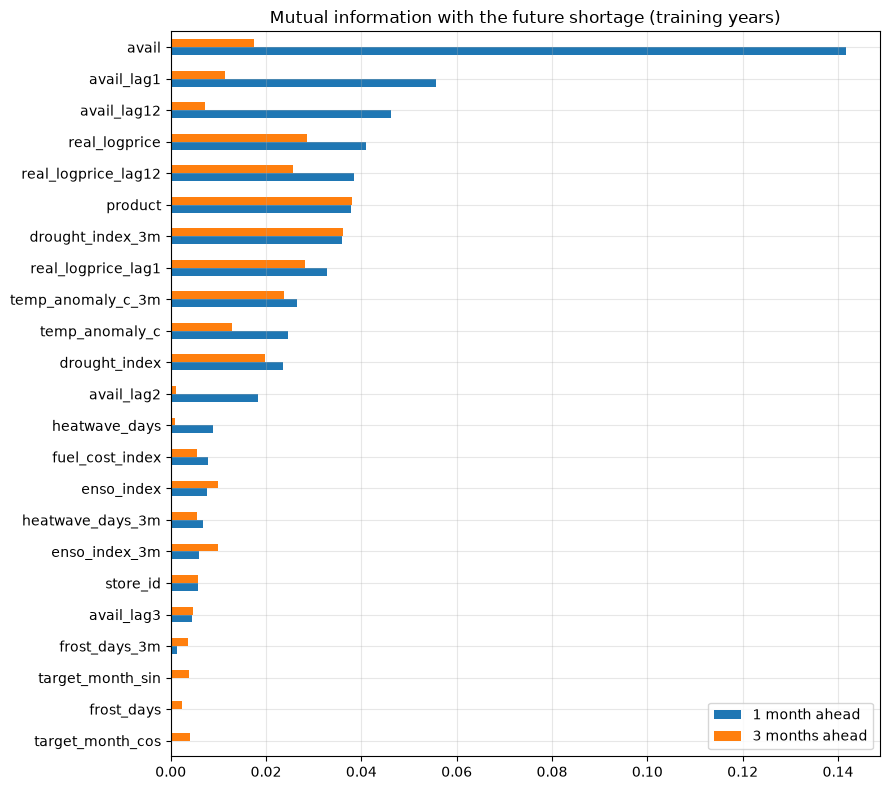

In [82]:
feats = pf.FEATURES
tr1, va1, te1 = pf.split_by_target_year(frames[1])
tr3, va3, te3 = pf.split_by_target_year(frames[3])

def mutual_info_table(tr):
    X = tr[pf.ALL_NUM].fillna(tr[pf.ALL_NUM].median())
    mi = pd.Series(mutual_info_classif(X, tr["y"], random_state=1), index=pf.ALL_NUM)
    for c in pf.CATEGORICAL:
        mi[c] = mutual_info_score(tr[c], tr["y"])
    return mi

mi = pd.DataFrame({"1 month ahead": mutual_info_table(tr1), "3 months ahead": mutual_info_table(tr3)})
mi = mi.sort_values("1 month ahead", ascending=True)
mi.plot.barh(figsize=(9, 8), title="Mutual information with the future shortage (training years)")
plt.tight_layout()
plt.show()

1 month(s) ahead:
availability (now and past)    0.448
inflation-adjusted price       0.069
weather and ENSO               0.053
month being predicted          0.036
store and product              0.033
fuel cost                      0.017

3 month(s) ahead:
inflation-adjusted price       0.175
store and product              0.168
weather and ENSO               0.070
month being predicted          0.061
availability (now and past)    0.031
fuel cost                      0.030



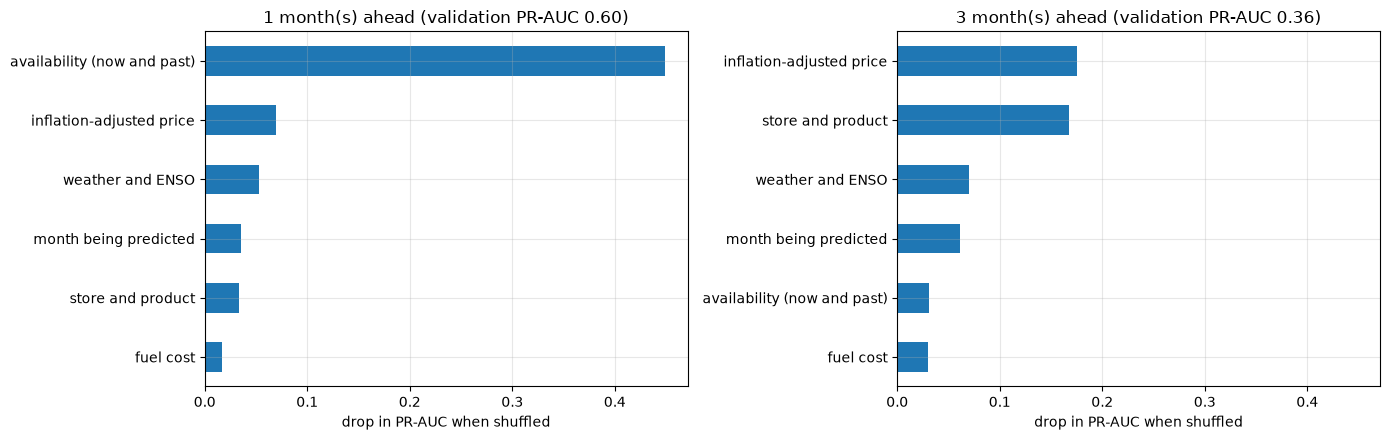

In [83]:
def predict_p(model, X):
    return model.predict_proba(pf.to_records(X))[:, 1]

def permutation_by_group(model, X, y, groups, n_repeats=5, seed=1):
    """Drop in PR-AUC when a group of columns is shuffled together."""
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, predict_p(model, X))
    out = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]
            drops.append(base - average_precision_score(y, predict_p(model, Xp)))
        out[name] = float(np.mean(drops))
    return pd.Series(out).sort_values(ascending=False), base

single = {c: [c] for c in feats}
groups = {
    "availability (now and past)": ["avail", "avail_lag1", "avail_lag2", "avail_lag3", "avail_lag12"],
    "inflation-adjusted price": ["real_logprice", "real_logprice_lag1", "real_logprice_lag12"],
    "weather and ENSO": pf.WEATHER_NUM,
    "month being predicted": ["target_month_sin", "target_month_cos"],
    "fuel cost": ["fuel_cost_index"],
    "store and product": pf.CATEGORICAL,
}

fits = {h: pf.make_model("xgboost").fit(pf.to_records(tr), tr["y"])
        for h, tr in [(1, tr1), (3, tr3)]}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for a, (h, va) in zip(ax, [(1, va1), (3, va3)]):
    g, base = permutation_by_group(fits[h], va[feats], va["y"], groups)
    g.iloc[::-1].plot.barh(ax=a, title=f"{h} month(s) ahead (validation PR-AUC {base:.2f})")
    a.set_xlabel("drop in PR-AUC when shuffled")
    print(f"{h} month(s) ahead:"); print(g.round(3).to_string()); print()
plt.tight_layout()
plt.show()

In [84]:
# The same, one feature at a time
top = {}
for h, va in [(1, va1), (3, va3)]:
    s, _ = permutation_by_group(fits[h], va[feats], va["y"], single)
    top[f"{h} month(s) ahead"] = s
top = pd.DataFrame(top).sort_values("1 month(s) ahead", ascending=False)
display(top.head(12).round(4))

,1 month(s) ahead,3 month(s) ahead
avail,0.4330,0.0044
real_logprice,0.0260,0.0564
store_id,0.0211,0.1307
product,0.0203,0.0405
target_month_cos,0.0196,0.0363
avail_lag2,0.0195,0.0026
fuel_cost_index,0.0183,0.0283
real_logprice_lag1,0.0153,0.0367
temp_anomaly_c,0.0130,0.0087
heatwave_days,0.0109,0.0018


**Importance takeaways**

- **One month ahead,** current and recent availability dominates: shuffling it cuts validation PR-AUC by about 0.45, more than six times any other group (inflation-adjusted price 0.07, weather 0.06, store and product 0.04, calendar month 0.04). The best single predictor of next month's shortage is whether things are already tight.
- **Three months ahead,** availability falls to 0.04 and the picture changes: inflation-adjusted price (0.19) and store and product (0.18) lead, followed by weather (0.09) and the calendar month (0.07). Weather's contribution rises from 0.06 to 0.09 as the horizon grows, in line with the idea that weather is more useful for looking further ahead.
- Inflation-adjusted price is useful at both horizons. In this data price and availability react to the same supply stress, so price acts as a second signal of trouble.
- Fuel cost adds little.

## 6. Model selection: baselines and four model families

 Model

 Logistic regression ,
 Decision tree ,
 Random forest ,
 XGBoost 

First a quick comparison with default settings on the **validation** years, with and without the weather features. The test years stay untouched.

In [85]:
def val_pr_auc(kind, num_cols, params=None):
    scores = []
    for h in HORIZONS:
        tr, va, _ = pf.split_by_target_year(frames[h])
        m = pf.make_model(kind, params).fit(pf.to_records(tr, num_cols), tr["y"])
        scores.append(average_precision_score(va["y"], m.predict_proba(pf.to_records(va, num_cols))[:, 1]))
    return scores

names = {"logistic": "logistic regression (baseline model)", "tree": "decision tree",
         "forest": "random forest", "xgboost": "XGBoost"}
rows = {}
for kind in pf.MODEL_KINDS:
    rows[f"{names[kind]} (no weather)"] = val_pr_auc(kind, pf.BASE_NUM)
    rows[f"{names[kind]} (+ weather)"] = val_pr_auc(kind, pf.ALL_NUM)

for label, col in [("baseline: never shortage", None), ("baseline: persistence", "persist"),
                   ("baseline: same month last year", "seasonal")]:
    rows[label] = [average_precision_score(pf.split_by_target_year(frames[h])[1]["y"],
                                           np.zeros(len(pf.split_by_target_year(frames[h])[1])) if col is None
                                           else pf.split_by_target_year(frames[h])[1][col]) for h in HORIZONS]

sel = pd.DataFrame(rows, index=[f"{h} month(s)" for h in HORIZONS]).T
sel["mean"] = sel.mean(axis=1)
sel = sel.sort_values("mean", ascending=False)
display(sel.round(3))

,1 month(s),2 month(s),3 month(s),mean
random forest (no weather),0.568,0.420,0.426,0.471
XGBoost (+ weather),0.601,0.434,0.362,0.466
XGBoost (no weather),0.594,0.417,0.367,0.460
random forest (+ weather),0.562,0.408,0.384,0.451
logistic regression (baseline model) (+ weather),0.596,0.365,0.289,0.416
logistic regression (baseline model) (no weather),0.547,0.300,0.243,0.363
decision tree (no weather),0.465,0.264,0.240,0.323
decision tree (+ weather),0.418,0.263,0.208,0.296
baseline: persistence,0.268,0.132,0.095,0.165
baseline: same month last year,0.158,0.158,0.158,0.158


**Reading the table (validation years, default settings)**

- Every model beats every baseline at every horizon. Persistence scores 0.27, 0.13 and 0.10 against 0.08 for no skill.
- At 1 month ahead logistic regression with weather (0.596) is as good as XGBoost with weather (0.599): the problem is close to linear in the availability signal. At 2 and 3 months the tree ensembles pull ahead (3 months: forest 0.42, XGBoost 0.38, logistic 0.24-0.29), because the longer-range signal is made of interactions between product, season and weather.
- Weather helps logistic regression (mean 0.36 -> 0.42) and XGBoost (0.44 -> 0.46), but not the random forest (0.47 -> 0.45) or the decision tree. On a single validation window these differences of a few hundredths are within the noise (compare the fold-to-fold spread in section 7), so the honest summary is that weather adds a little for some models and nothing detectable for others.
- A single decision tree is clearly the weakest model: it overfits a small number of shortages.
- The top three (forest, XGBoost, logistic with weather) are close, so section 7 uses cross-validation over three time blocks instead of one validation window to choose.

## 7. Cross-validation and hyperparameter tuning

**Time-ordered cross-validation.** Each fold trains on all predicted months *before* a block of years and scores on that block:

| Fold | Train (predicted years) | Score on |
|---|---|---|
| 1 | up to 2005 | 2006-2010 |
| 2 | up to 2010 | 2011-2015 |
| 3 | up to 2015 | 2016-2020 |

The test years (2021-2025) are not used. The tuning score is the mean PR-AUC over the three folds and the three horizons. We use random search (grid for logistic regression, which is small). Search spaces are a handful of values per parameter; the point is to see whether tuning matters, not to squeeze out the last hundredth.

In [86]:
FOLDS = [(2006, 2010), (2011, 2015), (2016, 2020)]
TRAIN_ALL = {h: frames[h][frames[h]["target_date"].dt.year <= pf.VAL_END] for h in HORIZONS}   # 1991-2020

def cv_scores(kind, params=None):
    """PR-AUC for every (horizon, fold): array of shape (3, 3)."""
    out = np.zeros((len(HORIZONS), len(FOLDS)))
    for i, h in enumerate(HORIZONS):
        d = TRAIN_ALL[h]
        year = d["target_date"].dt.year
        for j, (a, b) in enumerate(FOLDS):
            tr, va = d[year < a], d[(year >= a) & (year <= b)]
            m = pf.make_model(kind, params).fit(pf.to_records(tr), tr["y"])
            out[i, j] = average_precision_score(va["y"], predict_p(m, va))
    return out

spaces = {
    "logistic": ({"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10], "class_weight": [None, "balanced"]}, 14),
    "tree": ({"max_depth": [3, 4, 5, 6, 8, 10], "min_samples_leaf": [5, 10, 20, 40],
              "class_weight": [None, "balanced"]}, 14),
    "forest": ({"n_estimators": [100, 200, 300], "max_depth": [6, 10, 15, None],
                "min_samples_leaf": [3, 5, 10, 20], "max_features": ["sqrt", 0.3, 0.5]}, 10),
    "xgboost": ({"n_estimators": [100, 200, 400], "learning_rate": [0.02, 0.05, 0.1],
                 "max_depth": [2, 3, 4, 6], "min_child_weight": [1, 5, 10], "subsample": [0.7, 0.9],
                 "colsample_bytree": [0.5, 0.8], "reg_lambda": [1, 10], "scale_pos_weight": [1, 3]}, 18),
}

# default settings, then random search
results = {}
for kind in pf.MODEL_KINDS:
    default = cv_scores(kind)
    space, n_iter = spaces[kind]
    best = (default.mean(), None, default)
    tried = 0
    for p in ParameterSampler(space, n_iter=n_iter, random_state=1):
        s = cv_scores(kind, p)
        tried += 1
        if s.mean() > best[0]:
            best = (s.mean(), p, s)
    results[kind] = {"default": default, "best_params": best[1], "tuned": best[2], "tried": tried}
    print(f"{kind:9s} default {default.mean():.3f} -> tuned {best[2].mean():.3f}   ({tried} settings tried)  {best[1]}")

logistic  default 0.482 -> tuned 0.482   (14 settings tried)  {'class_weight': None, 'C': 3}
tree      default 0.350 -> tuned 0.371   (14 settings tried)  {'min_samples_leaf': 40, 'max_depth': 10, 'class_weight': None}
forest    default 0.493 -> tuned 0.495   (10 settings tried)  {'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}
xgboost   default 0.500 -> tuned 0.501   (18 settings tried)  {'subsample': 0.9, 'scale_pos_weight': 3, 'reg_lambda': 10, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


In [87]:
# Baselines under the same folds, for the summary table
def cv_baseline(col):
    out = np.zeros((len(HORIZONS), len(FOLDS)))
    for i, h in enumerate(HORIZONS):
        d = TRAIN_ALL[h]; year = d["target_date"].dt.year
        for j, (a, b) in enumerate(FOLDS):
            va = d[(year >= a) & (year <= b)]
            out[i, j] = average_precision_score(va["y"], va[col])
    return out

summary = []
for kind in pf.MODEL_KINDS:
    r = results[kind]
    for label, s in [("default", r["default"]), ("tuned", r["tuned"])]:
        summary.append({"model": names[kind], "settings": label,
                        "CV PR-AUC mean": s.mean(), "std across folds": s.mean(axis=0).std(),
                        "1 month": s[0].mean(), "2 months": s[1].mean(), "3 months": s[2].mean()})
for label, col in [("persistence", "persist"), ("same month last year", "seasonal")]:
    s = cv_baseline(col)
    summary.append({"model": f"baseline: {label}", "settings": "-", "CV PR-AUC mean": s.mean(),
                    "std across folds": s.mean(axis=0).std(), "1 month": s[0].mean(),
                    "2 months": s[1].mean(), "3 months": s[2].mean()})
cv_table = pd.DataFrame(summary).sort_values("CV PR-AUC mean", ascending=False).reset_index(drop=True)
display(cv_table.round(3))

,model,settings,CV PR-AUC mean,std across folds,1 month,2 months,3 months
0,XGBoost,tuned,0.501,0.070,0.649,0.457,0.398
1,XGBoost,default,0.500,0.080,0.663,0.451,0.385
2,random forest,tuned,0.495,0.080,0.633,0.454,0.397
3,random forest,default,0.493,0.081,0.630,0.450,0.397
4,logistic regression (baseline model),tuned,0.482,0.066,0.665,0.442,0.340
5,logistic regression (baseline model),default,0.482,0.066,0.665,0.443,0.339
6,decision tree,tuned,0.371,0.061,0.543,0.313,0.256
7,decision tree,default,0.350,0.070,0.519,0.298,0.235
8,baseline: persistence,-,0.201,0.056,0.331,0.163,0.108
9,baseline: same month last year,-,0.197,0.028,0.197,0.197,0.197


In [88]:
# Show the tuned winners and how much each fold varies
rows = []
for kind in pf.MODEL_KINDS:
    s = results[kind]["tuned"]
    rows.append({"model": names[kind], **{f"fold {a}-{b}": s[:, j].mean() for j, (a, b) in enumerate(FOLDS)},
                 "best parameters": results[kind]["best_params"] or "defaults"})
display(pd.DataFrame(rows).set_index("model").round(3))

,fold 2006-2010,fold 2011-2015,fold 2016-2020,best parameters
model,,,,
logistic regression (baseline model),0.572,0.458,0.416,"{'class_weight': None, 'C': 3}"
decision tree,0.457,0.326,0.329,"{'min_samples_leaf': 40, 'max_depth': 10, 'cla..."
random forest,0.606,0.424,0.453,"{'n_estimators': 200, 'min_samples_leaf': 5, '..."
XGBoost,0.591,0.421,0.491,"{'subsample': 0.9, 'scale_pos_weight': 3, 'reg..."


In [89]:
# Why not shuffled K-fold? Same model, same data (1991-2020, 1 month ahead).
from sklearn.model_selection import KFold
d = TRAIN_ALL[1]
bp = results["xgboost"]["best_params"]
sc = []
for tr_i, va_i in KFold(5, shuffle=True, random_state=1).split(d):
    tr, va = d.iloc[tr_i], d.iloc[va_i]
    m = pf.make_model("xgboost", bp).fit(pf.to_records(tr), tr["y"])
    sc.append(average_precision_score(va["y"], predict_p(m, va)))
honest = results["xgboost"]["tuned"][0]
print(f"shuffled 5-fold PR-AUC : {np.mean(sc):.3f}")
print(f"time-ordered PR-AUC    : {honest.mean():.3f}  (1 month ahead, same model)")

shuffled 5-fold PR-AUC : 0.693
time-ordered PR-AUC    : 0.649  (1 month ahead, same model)


**Reading the cross-validation results**

- **Scores are close at the top.** Tuned XGBoost (0.500), random forest (0.496) and logistic regression (0.482) differ by less than the spread across folds (the fold scores of one model range from about 0.41 to 0.60), so they are effectively tied. XGBoost has the highest mean, so it is selected. A single decision tree (0.38) is clearly worse, and every model is about 2.5 times better than persistence (0.20) or last year's value (0.20).
- **The baseline model is strong at 1 month** (0.665, the best of all at that horizon) and falls behind at 3 months (0.34 against 0.40 for forest and XGBoost). The extra complexity of tree ensembles pays off only for longer horizons.
- **Tuning changed little** for logistic regression, forest and XGBoost (+0.00), and helped the decision tree (0.34 -> 0.38) by allowing deeper trees with larger leaves. The default settings were already reasonable.
- **Scores fall in later folds** (mean over models: roughly 0.57 for 2006-10, 0.41 for 2011-15, 0.42 for 2016-20), partly because shortages become rarer over time (see the EDA), which lowers PR-AUC for the same skill.
- **Shuffled K-fold flatters the score:** 0.698 against 0.647 for the same model at 1 month ahead, because it trains on months that come after the ones it scores. Time-ordered folds are the honest estimate.

In [91]:
# Choose the final model by cross-validated PR-AUC and save its settings for train.py
best_kind = max(pf.MODEL_KINDS, key=lambda k: results[k]["tuned"].mean())
config = {"kind": best_kind, "params": results[best_kind]["best_params"] or {},
          "cv_pr_auc_mean": round(float(results[best_kind]["tuned"].mean()), 4),
          "selected_by": "mean PR-AUC over 3 time-ordered folds and horizons 1-3 (target years 2006-2020)"}
with open("model_config.json", "w") as f:
    json.dump(config, f, indent=2)
print(json.dumps(config, indent=2))

{
  "kind": "xgboost",
  "params": {
    "subsample": 0.9,
    "scale_pos_weight": 3,
    "reg_lambda": 10,
    "n_estimators": 200,
    "min_child_weight": 1,
    "max_depth": 6,
    "learning_rate": 0.1,
    "colsample_bytree": 0.8
  },
  "cv_pr_auc_mean": 0.5011,
  "selected_by": "mean PR-AUC over 3 time-ordered folds and horizons 1-3 (target years 2006-2020)"
}


## 8. Threshold: precision, recall and F1

The model outputs a probability. A warning needs a cutoff. With 9% positives the default 0.5 would miss many shortages, so we choose the cutoff on the **validation** years (model fit on training years only) by maximising F1, then keep it fixed. A store that finds a missed shortage costlier than a false alarm can move it lower.

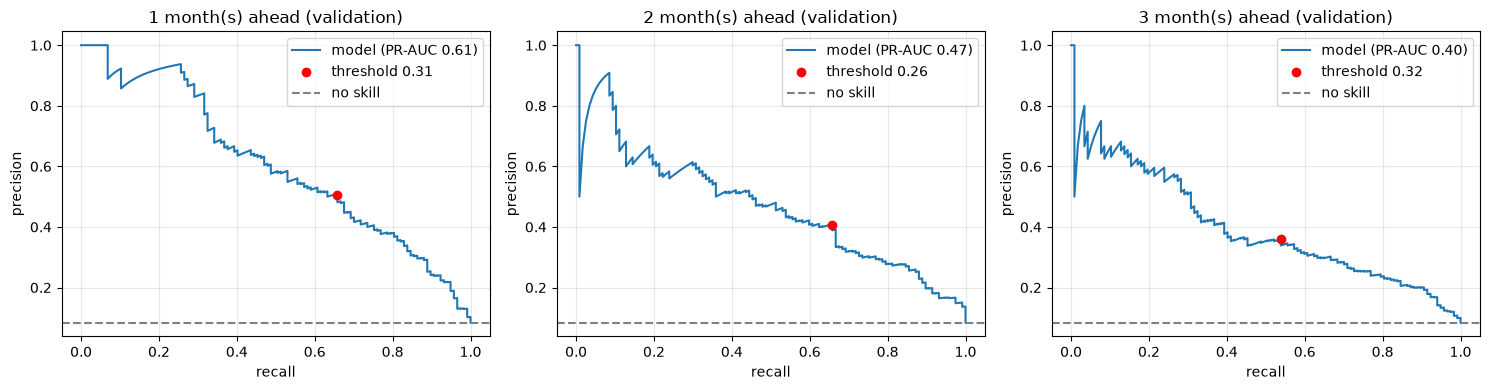

,threshold,precision,recall,F1,warnings
0,0.10,0.357,0.812,0.496,266
1,0.20,0.420,0.718,0.530,200
2,0.30,0.500,0.658,0.568,154
3,0.31,0.507,0.658,0.572,152
4,0.40,0.531,0.581,0.555,128
5,0.50,0.569,0.530,0.549,109
6,0.60,0.628,0.462,0.532,86


In [92]:
chosen = {}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, h in zip(ax, HORIZONS):
    tr, va, _ = pf.split_by_target_year(frames[h])
    m = pf.make_model(best_kind, config["params"]).fit(pf.to_records(tr), tr["y"])
    p = predict_p(m, va)
    chosen[h] = pf.best_f1_threshold(va["y"], p)
    prec, rec, thr = precision_recall_curve(va["y"], p)
    a.plot(rec, prec, label=f"model (PR-AUC {average_precision_score(va['y'], p):.2f})")
    pr, rc = pf.precision_recall_at(va["y"], p >= chosen[h])
    a.scatter([rc], [pr], color="red", zorder=3, label=f"threshold {chosen[h]:.2f}")
    a.axhline(va["y"].mean(), color="gray", ls="--", label="no skill")
    a.set_title(f"{h} month(s) ahead (validation)"); a.set_xlabel("recall"); a.set_ylabel("precision"); a.legend()
plt.tight_layout(); plt.show()

# Precision / recall / F1 at several cutoffs for 1 month ahead
tr, va, _ = pf.split_by_target_year(frames[1])
m = pf.make_model(best_kind, config["params"]).fit(pf.to_records(tr), tr["y"])
p = predict_p(m, va)
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, chosen[1]]:
    pr, rc = pf.precision_recall_at(va["y"], p >= t)
    rows.append({"threshold": round(t, 3), "precision": pr, "recall": rc, "F1": 2 * pr * rc / (pr + rc) if pr + rc else 0,
                 "warnings": int((p >= t).sum())})
display(pd.DataFrame(rows).sort_values("threshold").round(3).reset_index(drop=True))

## 9. Final evaluation on the untouched test years (2021-2025)

For each horizon: refit the chosen model on training + validation years (1991-2020), apply the threshold chosen above, and score the test years once. This is exactly what `train.py` does.

In [28]:
final_rows, test_pred = [], {}
for h in HORIZONS:
    tr, va, te = pf.split_by_target_year(frames[h])
    trva = pd.concat([tr, va])
    m = pf.make_model(best_kind, config["params"]).fit(pf.to_records(trva), trva["y"])
    p = predict_p(m, te)
    warn = p >= chosen[h]
    pr, rc = pf.precision_recall_at(te["y"], warn)
    test_pred[h] = te.assign(p=p, warn=warn.astype(int))
    final_rows.append({"horizon": h, "model PR-AUC": average_precision_score(te["y"], p),
                       "ROC-AUC": roc_auc_score(te["y"], p),
                       "precision": pr, "recall": rc, "F1": 2 * pr * rc / (pr + rc) if pr + rc else 0,
                       "persistence PR-AUC": average_precision_score(te["y"], te["persist"]),
                       "same month last year PR-AUC": average_precision_score(te["y"], te["seasonal"]),
                       "no-skill PR-AUC": te["y"].mean(), "test rows": len(te), "test shortages": int(te["y"].sum())})
final = pd.DataFrame(final_rows).set_index("horizon")
display(final.round(3))

,model PR-AUC,ROC-AUC,precision,recall,F1,persistence PR-AUC,same month last year PR-AUC,no-skill PR-AUC,test rows,test shortages
horizon,,,,,,,,,,
1,0.611,0.930,0.493,0.595,0.539,0.309,0.182,0.083,1390,116
2,0.445,0.879,0.485,0.431,0.457,0.217,0.182,0.083,1390,116
3,0.425,0.871,0.478,0.371,0.417,0.118,0.182,0.083,1390,116


In [29]:
# Is the predicted probability trustworthy? Compare predicted and actual shortage rates (1 month ahead)
g = test_pred[1]
bins = pd.cut(g["p"], [0, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0], include_lowest=True)
cal = g.groupby(bins, observed=True).agg(rows=("y", "size"), mean_predicted=("p", "mean"), actual_rate=("y", "mean"))
display(cal.round(3))

# By product (1 month ahead)
by_prod = g.groupby("product").apply(lambda x: pd.Series({
    "rows": len(x), "shortages": int(x["y"].sum()),
    "recall": x.loc[x["y"] == 1, "warn"].mean() if x["y"].sum() else np.nan,
    "PR-AUC": average_precision_score(x["y"], x["p"]) if x["y"].sum() else np.nan}))
display(by_prod.round(2))

,rows,mean_predicted,actual_rate
p,,,
"(-0.001, 0.02]",939,0.004,0.006
"(0.02, 0.05]",105,0.032,0.048
"(0.05, 0.1]",90,0.072,0.100
"(0.1, 0.2]",81,0.150,0.222
"(0.2, 0.4]",53,0.301,0.226
"(0.4, 0.7]",69,0.535,0.377
"(0.7, 1.0]",53,0.858,0.755


,rows,shortages,recall,PR-AUC
product,,,,
apples,114.0,8.0,0.75,0.78
avocados,113.0,14.0,0.71,0.57
bananas,116.0,2.0,0.00,0.16
broccoli,114.0,25.0,0.64,0.80
carrots,118.0,1.0,0.00,0.12
grapes,115.0,9.0,0.11,0.16
lettuce,117.0,14.0,0.57,0.66
onions,119.0,0.0,NaN,NaN
oranges,117.0,8.0,0.25,0.46


**Reading the test results**

- The final model beats every baseline at every horizon: test PR-AUC **0.61, 0.45 and 0.43** for 1, 2 and 3 months ahead, against 0.31, 0.22 and 0.12 for persistence, 0.18 for same-month-last-year and 0.08 for no skill. ROC-AUC is 0.93, 0.88 and 0.87.
- At the validation-chosen threshold, one month ahead the model catches 60% of shortages (recall 0.60) and 49% of its warnings are real shortages (precision 0.49). At 3 months it catches 37% with precision 0.48. Warnings get less complete as the horizon grows.
- **Probabilities are not calibrated.** The model was trained with `scale_pos_weight=3`, which pushes probabilities up: rows predicted at 40-70% had an actual shortage rate of 38%, and rows predicted at 70-100% had 76%. Use the probability to rank risk and the threshold for yes/no warnings, not as a literal chance.
- Results differ a lot by product. Strawberries (recall 0.78, PR-AUC 0.87), apples, avocados, tomatoes and broccoli are caught reasonably well; grapes (1 of 9), oranges, bananas and carrots are not, and potatoes and onions had no shortage at all in the test years. Per-product numbers rest on very few shortages and should not be over-read.

## Summary

| Question | Finding |
|---|---|
| How much warning can a model give? | Useful at 1 month (PR-AUC 0.61), still clearly better than baselines at 3 months (0.43). Recall falls from 0.60 to 0.37 over that range. |
| Does weather help beyond past availability? | A little. Weather matters more at 3 months than at 1 month in the importance analysis and helps logistic regression and XGBoost on validation, but changes the random forest by less than the noise. |
| What matters most? | Current availability at 1 month ahead; inflation-adjusted price, store and product, weather and calendar month at 3 months ahead. |
| Which model? | XGBoost, by a small margin. Logistic regression is nearly as good at 1 month, a forest is nearly as good everywhere. |

**Limitations.** The data is simulated, so this validates the method rather than describing the real produce market. The test set has only 116 shortages and covers an unusual stretch (the 2021 spike, then calm years), so results could shift on another period, and the top three model families are statistically tied. The final model is trained by `train.py`, served by `serve.py` and packaged by the `Dockerfile`.